# Module 8 Lab 2: Textbook Problem 9.1, AI-Assisted

## Step 1: Ground Truth Before AI

### Load the Dataset


In [1]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


### Dataset Shape

In [2]:
print("Dataset shape:", df.shape)

Dataset shape: (50, 6)


In [3]:
print("Missing values by column:")
print(df.isnull().sum())

Missing values by column:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64


### Column Means
Calculate the mean of each numerical variable before using AI.

In [4]:
print("Mean of each numerical column:")
print(df.mean(numeric_only=True))

Mean of each numerical column:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


## Step 2: ChatGPT-Assisted Clustering

### Prompt Log

I have a dataset containing 50 countries and five numerical variables: sr, pop15, pop75, dpi, and ddpi. The country-name column is called Contry.

I independently verified the following:

- Dataset shape: (50, 6)
- Missing values: 0 in every column
- Column means:
  - sr = 9.6710
  - pop15 = 35.0896
  - pop75 = 2.2930
  - dpi = 1106.7584
  - ddpi = 3.7576

Help me use agglomerative clustering to identify groups of similar countries based on their savings-related characteristics.

Provide commented Python code for Google Colab that standardizes the numerical variables, preserves country names, and creates a labeled dendrogram.

Explain how to choose the number of clusters and interpret their characteristics. Do not assume or invent results before running the code.

### AI Response 1: Data Preparation

The AI suggested standardizing the five numerical variables before agglomerative clustering because they have different measurement scales.

In [5]:
from sklearn.preprocessing import StandardScaler

# Select the five numerical variables for clustering
features = ["sr", "pop15", "pop75", "dpi", "ddpi"]
X = df[features]

# Standardize the variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check the standardized data
print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (50, 5)


### AI Response 1: Agglomerative Clustering

"Use hierarchical agglomerative clustering to group countries with similar characteristics. Display a labeled dendrogram to visualize how countries are grouped."

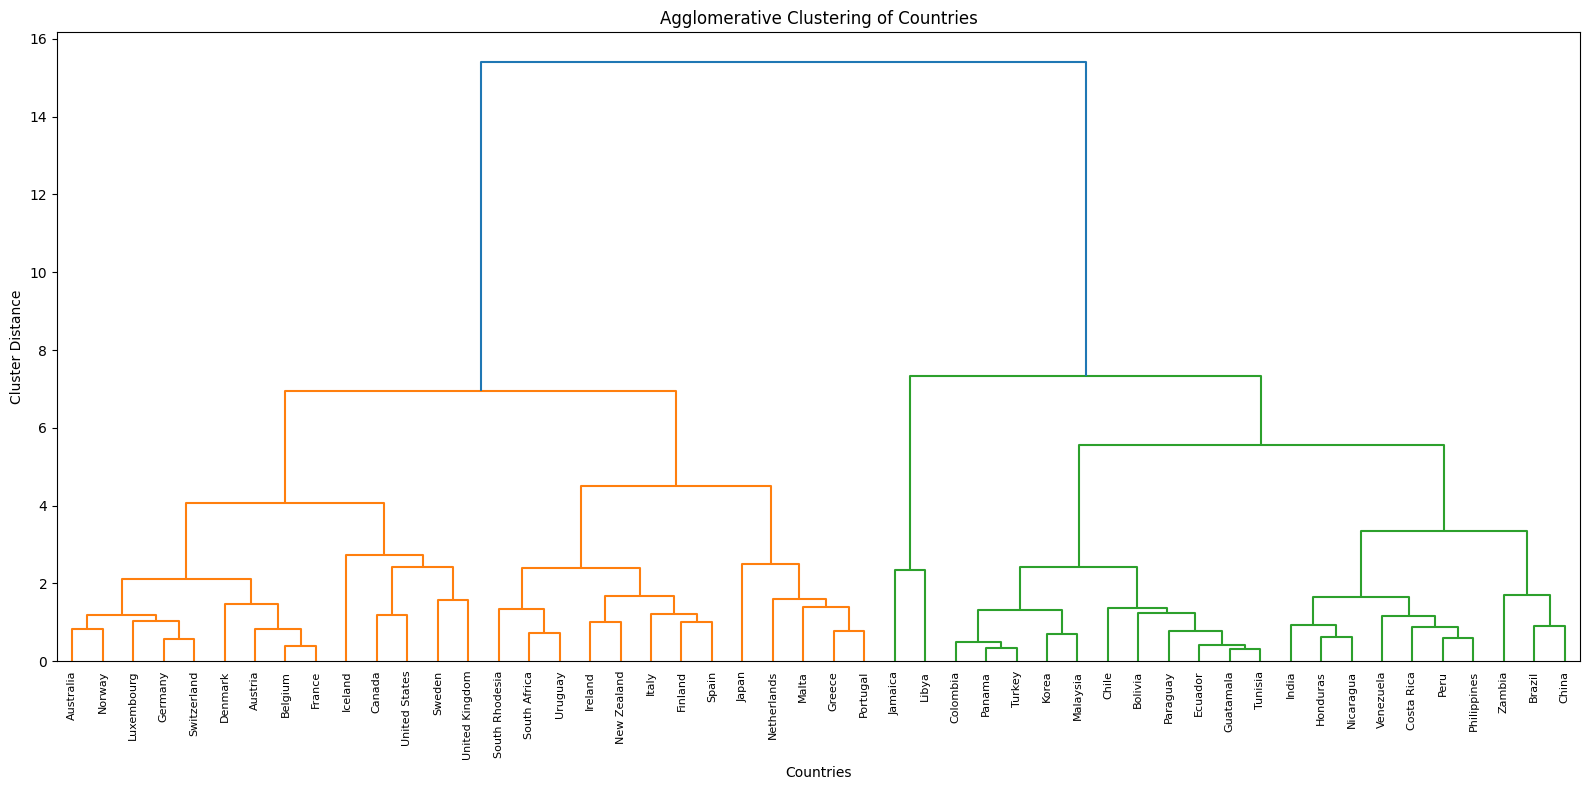

In [6]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Perform agglomerative clustering on standardized data
Z = linkage(X_scaled, method="ward")

# Display the dendrogram with country names
plt.figure(figsize=(16, 8))
dendrogram(Z, labels=df["Contry"].values, leaf_rotation=90)

plt.title("Agglomerative Clustering of Countries")
plt.xlabel("Countries")
plt.ylabel("Cluster Distance")
plt.tight_layout()
plt.show()

## The AI suggested using two clusters based on the two main branches of the dendrogram. The following code assigns countries to these clusters and displays the number of countries in each group.

In [7]:
from scipy.cluster.hierarchy import fcluster

# Assign each country to one of two clusters
df["cluster"] = fcluster(Z, t=2, criterion="maxclust")

# Display the number of countries in each cluster
print("Countries per cluster:")
print(df["cluster"].value_counts().sort_index())

Countries per cluster:
cluster
1    27
2    23
Name: count, dtype: int64


## The AI suggested calculating the mean of each numerical variable for both clusters to identify differences in their savings-related characteristics.

In [8]:
# Calculate the mean of each variable for each cluster
cluster_means = df.groupby("cluster")[features].mean()

print("Mean values by cluster:")
print(cluster_means.round(2))

Mean values by cluster:
            sr  pop15  pop75      dpi  ddpi
cluster                                    
1        11.60  27.24   3.31  1763.29  3.79
2         7.41  44.30   1.10   336.05  3.72


### AI Code Execution Log
Chart GPT documented
"
- Standardization: Successful. Output shape: (50, 5).
- Agglomerative clustering: Successful. Labeled dendrogram generated.
- Cluster selection: Two clusters identified (27 and 23 countries).
- Cluster means: Calculated successfully for all five numerical variables.
- Errors or corrections: None. All AI-generated code ran successfully".

## Step 3: My Verification

### Verify Cluster 1

I will independently calculate the mean values for Cluster 1 using groupby() and compare them with the overall dataset means to check the AI's interpretation.

In [9]:
my_cluster_means = df.groupby("cluster")[features].mean().loc[1]

# Calculate overall means for comparison
overall_means = df[features].mean()

# Compare the results
comparison = pd.DataFrame({
    "Overall Mean": overall_means,
    "Cluster 1 Mean": my_cluster_means
})

print(comparison.round(2))

       Overall Mean  Cluster 1 Mean
sr             9.67           11.60
pop15         35.09           27.24
pop75          2.29            3.31
dpi         1106.76         1763.29
ddpi           3.76            3.79


### My Conclusion

My groupby() calculation confirms the AI's claim about Cluster 1. Compared with the overall dataset, Cluster 1 has a higher average savings ratio and disposable income, a smaller percentage of people under 15, and a larger percentage of people over 75. The average income growth rate is almost the same.

# Step 4: Interpretation and Caution
The clustering identified two groups of countries with different savings, income, and population characteristics. Countries in Cluster 1 generally have higher savings and disposable income, while countries in Cluster 2 have a larger proportion of younger people. However, the clusters do not show that demographic differences cause changes in savings behavior. Since I am still  starting to learn clustering, I cannot fully evaluate the AI's choice of method or number of clusters, even though I verified the numerical results.

## Step 5: Bonus Verification — Textbook Comparison
Chapter 9 demonstrates how the same observations can produce different dendrograms depending on how distances between clusters are calculated. Figures 9.1 and 9.2 illustrate this difference using maximum and minimum distances, while Figures 9.3 and 9.4 show how changing the distance threshold changes the number of clusters. In my lab  the Chat GPT  used Ward linkage and suggested dividing the countries into two groups based on the main branches of the dendrogram. This comparison helped me recognize that the number of clusters depends on methodological choices rather than being a fixed property of the dataset.